# Parallel nodes Execution in Agentic Systems

LangGraph provides robust support for parallel execution of nodes, enhancing the efficiency and performance of graph-based agentic workflows.

In [2]:
import os
from dotenv import load_dotenv, find_dotenv
load_dotenv()

True

In [3]:
from IPython.display import Image, display

from typing import Any
from typing_extensions import TypedDict
from typing import Annotated
import operator
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    question: str
    answer: str
    context: Annotated[list, operator.add]

In [4]:
from langchain_core.messages import HumanMessage, SystemMessage

from langchain_community.document_loaders import WikipediaLoader
from langchain_community.tools import TavilySearchResults

/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_81877/3419359532.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WikipediaLoader


In [5]:
def search_web(state):
    
    """ Retrieve docs from web search """
    print('--Getting Info from the Web--')

    # Search
    tavily_search = TavilySearchResults(max_results=3)
    search_docs = tavily_search.invoke(state['question'])
    print(f'''search_doc:{search_docs}''')
     # Format
    formatted_search_docs = "\n\n---\n\n".join(
        [
            f'''Content: {doc['content']}\nSource: {doc['url']}'''
            for doc in search_docs
        ]
    )
    print(f'''formatted_search_docs:{formatted_search_docs}''')
    return {"context": [formatted_search_docs]}

In [6]:
def search_wikipedia(state):
    
    """ Retrieve docs from wikipedia """
    print('--Getting Info from the Wikipedia--')

    # Search
    search_docs = WikipediaLoader(query=state['question'],
                                  load_max_docs=2).load()
    print(f'''wikipedia_search_docs:{search_docs}''')
     # Format
    formatted_search_docs = "\n\n---\n\n".join(
        [
            f'''Content: {doc.page_content}\nSource: {doc.metadata["source"]}'''
            for doc in search_docs
        ]
    )

    return {"context": [formatted_search_docs]}

In [ ]:
search_docs = WikipediaLoader(query="Python programming",
                                  load_max_docs=2).load()
    

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [12]:
search_docs

[Document(metadata={'title': 'Python (programming language)', 'summary': 'Python is a high-level, general-purpose programming language that emphasizes code readability, simplicity, and ease-of-writing with the use of significant indentation, an extensive ("batteries-included") standard library, and garbage collection. Python supports multiple programming paradigms but with an emphasis on object-oriented programming and dynamic typing.\nGuido van Rossum began working on Python in the late 1980s as a successor to the ABC programming language. Python 3.0, released in 2008, was a major revision and not completely backward-compatible with earlier versions. Beginning with Python 3.5, capabilities and keywords for typing were added to the language, allowing optional static typing. As of 2026, the Python Software Foundation supports Python 3.10, 3.11, 3.12, 3.13, and 3.14, following the project\'s annual release cycle and five-year support policy. Python 3.15.0rc1 (which defaults to UTF-8) is 

In [7]:
def generate_answer(state):
    
    """ Node to answer a question """
    print('--Generating final answer--')

    # Get state
    context = state["context"]
    question = state["question"]

    # Template
    answer_template = """Answer the question {question}
                         using these context documents: {context}"""
    answer_instructions = answer_template.format(question=question,
                                                       context=context)

    # Answer
    answer = llm.invoke([SystemMessage(content=answer_instructions)]+[HumanMessage(content=f"Answer the question.")])

    # Append it to state
    return {"answer": answer}

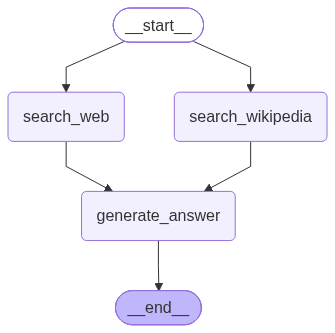

In [8]:
# Add nodes
builder = StateGraph(State)

# Initialize each node with node_secret
builder.add_node("search_web",search_web)
builder.add_node("search_wikipedia", search_wikipedia)
builder.add_node("generate_answer", generate_answer)

# Flow
# fan out
builder.add_edge(START, "search_wikipedia")
builder.add_edge(START, "search_web")
# fan in
builder.add_edge("search_wikipedia", "generate_answer")
builder.add_edge("search_web", "generate_answer")
# aggregation
builder.add_edge("generate_answer", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [9]:
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

In [11]:
result = graph.invoke({"question": "Tell me about Nvidia and its growth"})

--Getting Info from the Web--
--Getting Info from the Wikipedia--
search_doc:[{'title': 'How Nvidia Engineered a Successful Growth Strategy - Leyton Canada', 'url': 'https://leyton.com/ca/en/insights/articles/how-nvidia-engineered-a-successful-growth-strategy', 'content': '## Nvidia’s Growth Strategy\n\nAt the heart of Nvidia’s growth strategy lies an unwavering commitment to continuous innovation, and research and development. The company has consistently invested heavily in R&D, with expenditures skyrocketing from $2.38 billion in 2019 to a staggering $8.68 billion in 2024, marking a 73% increase over five years. This substantial investment underscores Nvidia’s determination to maintain its technological edge and market dominance, particularly in the AI chip sector where it currently holds an 80% market share. The company’s R&D efforts are deeply rooted in collaboration and open innovation, fostering partnerships with academia, research institutions, and industry leaders.', 'score': 

JSONDecodeError: Expecting value: line 1 column 1 (char 0)